# Central Cairo: where are everyday amenities concentrated?

Question: on a 300 m hexagonal grid over central Cairo, which cells combine the most amenities with the most variety, and where do cafes cluster?

Data: OpenStreetMap amenities (c) OpenStreetMap contributors, ODbL, saved in `showcase/data/`. The notebook runs offline.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / 'showcase').exists():
    root = root.parent
sys.path.insert(0, str(root / 'showcase'))
import make_showcase as ms  # reuses the constants and the library calls

amenities = gpd.read_file(ms.DATA_FILE)
print(len(amenities), 'amenities, CRS', amenities.crs)
amenities['amenity'].value_counts().to_frame('count')

mkdir -p failed for path /home/agent/.cache/matplotlib: [Errno 13] Permission denied: '/home/agent/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-3p70fj8c because there was an issue with the default path (/home/agent/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


441 amenities, CRS EPSG:4326


,count
amenity,
restaurant,158
cafe,117
bank,58
hospital,43
school,25
pharmacy,23
clinic,11
university,6


## Run the tool

Amenities are projected to UTM zone 36N (EPSG:32636, metres). The grid, join, score and DBSCAN clustering come from the `hexanalysis` package.

In [2]:
hexes, amenities_m, hotspots = ms.run_analysis()
print(ms.WORK_CRS, '| hex radius', ms.HEX_RADIUS_M, 'm | DBSCAN eps', ms.DBSCAN_EPS_M, 'm, min_samples', ms.DBSCAN_MIN_SAMPLES)
print(len(hexes), 'hexes,', len(hotspots), 'cafe hotspots')

EPSG:32636 | hex radius 300.0 m | DBSCAN eps 150.0 m, min_samples 4
126 hexes, 6 cafe hotspots


## Inspect the results

Top cells by score (density 65%, diversity 35%).

In [3]:
cols = ['hex_id', 'count', 'diversity', 'density_per_km2', 'score']
hexes.sort_values('score', ascending=False)[cols].head(8).round(2).reset_index(drop=True)

,hex_id,count,diversity,density_per_km2,score
0,27,34,5,145.41,0.94
1,56,28,5,119.75,0.83
2,55,22,5,94.09,0.71
3,67,22,4,94.09,0.65
4,66,22,4,94.09,0.65
5,17,14,6,59.87,0.62
6,80,9,6,38.49,0.52
7,26,13,4,55.60,0.48


In [4]:
hotspots.assign(lon=hotspots.to_crs(4326).geometry.x.round(4), lat=hotspots.to_crs(4326).geometry.y.round(4)).drop(columns='geometry')

,cluster,size,lon,lat
0,0,21,31.2228,30.0595
1,1,7,31.2380,30.0475
2,2,5,31.2383,30.0437
3,3,14,31.2420,30.0484
4,4,4,31.2216,30.0651
5,5,4,31.2450,30.0510


## Map

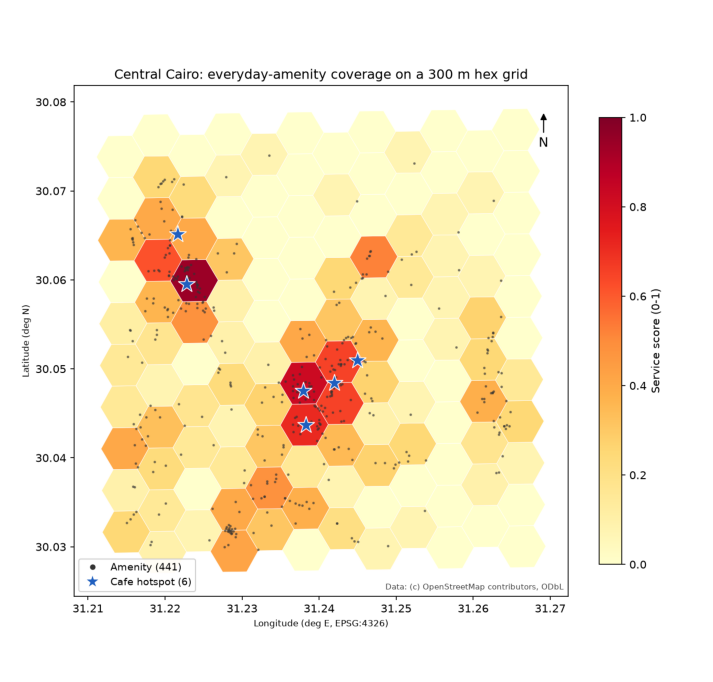

In [5]:
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    png = Path(tmp) / 'map.png'
    ms.make_png(hexes, amenities_m, hotspots, png)
    img = plt.imread(png)
%matplotlib inline
fig, ax = plt.subplots(figsize=(9, 8.6))
ax.imshow(img)
ax.axis('off')
plt.show()